# Part 3 — A Controlled Study of CLIP's Limitations: "on" versus "under"

Can CLIP tell "A mug on a table" from "A mug under a table"? Run `python tools/prepare_part3.py` once first to get the data.

In [1]:
import json
import os
import platform
import warnings
from math import comb
from pathlib import Path

os.environ.setdefault("HF_HUB_VERBOSITY", "error")
os.environ.setdefault("HF_HUB_DISABLE_SYMLINKS_WARNING", "1")  # Windows-only cache notice, not relevant to results
warnings.filterwarnings("ignore", message=".*unauthenticated requests.*")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import transformers
from PIL import Image, ImageOps
from transformers import CLIPModel, CLIPProcessor

ROOT = Path.cwd()
DATA = ROOT / "data"
OUT = ROOT / "outputs" / "part3"
OUT.mkdir(parents=True, exist_ok=True)

torch.manual_seed(0)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

CHECKPOINT = "openai/clip-vit-base-patch32"
model = CLIPModel.from_pretrained(CHECKPOINT).to(device).eval()
processor = CLIPProcessor.from_pretrained(CHECKPOINT)

try:  # record the exact revision of the checkpoint on the Hugging Face Hub
    from huggingface_hub import HfApi
    checkpoint_commit = HfApi().model_info(CHECKPOINT).sha
except Exception as exc:
    checkpoint_commit = f"unavailable ({type(exc).__name__})"

env = {
    "python": platform.python_version(),
    "torch": torch.__version__,
    "transformers": transformers.__version__,
    "numpy": np.__version__,
    "pillow": Image.__version__,
    "device": str(device),
    "processor": platform.processor(),
    "os": platform.platform(),
    "checkpoint": CHECKPOINT,
    "checkpoint_commit": checkpoint_commit,
}
(OUT / "environment.json").write_text(json.dumps(env, indent=2))
env

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

{'python': '3.13.2',
 'torch': '2.14.0+cpu',
 'transformers': '5.19.0',
 'numpy': '2.2.2',
 'pillow': '12.3.0',
 'device': 'cpu',
 'processor': 'Intel64 Family 6 Model 165 Stepping 2, GenuineIntel',
 'os': 'Windows-11-10.0.26300-SP0',
 'checkpoint': 'openai/clip-vit-base-patch32',
 'checkpoint_commit': '3d74acf9a28c67741b2f4f2ea7635f0aaf6f0268'}

## Task 1 — Hypothesis and comparison sets

### Hypothesis

> **H1.** When two captions differ only in "on" vs. "under", CLIP will pick the right one close to chance (50%) and get both images in a set right in fewer than half the sets.

### Data

27 on/under sets from What'sUp, Controlled Images A (Kamath, Hessel & Chang, EMNLP 2023), chosen by fixed rules in `tools/prepare_part3.py` and using the dataset's own captions.

In [2]:
pairs = pd.read_csv(DATA / "part3_pairs.csv")
N = len(pairs)
assert N >= 10 and all((ROOT / f).exists() for f in pd.concat([pairs.image_on, pairs.image_under]))
print(f"{N} comparison sets, {2 * N} images, {2 * N} descriptions")
sizes = {Image.open(ROOT / f).size for f in pd.concat([pairs.image_on, pairs.image_under])}
print("image sizes in the collection:", sizes)
with pd.option_context("display.max_rows", 100, "display.max_colwidth", 60):
    display(pairs[["set_id", "object", "caption_on", "caption_under"]])

27 comparison sets, 54 images, 54 descriptions
image sizes in the collection: {(1280, 960)}


,set_id,object,caption_on,caption_under
0,1,ball-of-yarn,A ball of yarn on a table,A ball of yarn under a table
1,2,banana,A banana on a table,A banana under a table
2,3,book,A book on a table,A book under a table
3,4,bottle,A bottle on a table,A bottle under a table
4,5,bowl,A bowl on a table,A bowl under a table
5,6,cap,A cap on a table,A cap under a table
6,7,cup,A cup on a table,A cup under a table
7,8,dog,A dog on a table,A dog under a table
8,9,dragonfruit,A dragonfruit on a table,A dragonfruit under a table
9,10,helmet,A helmet on a table,A helmet under a table


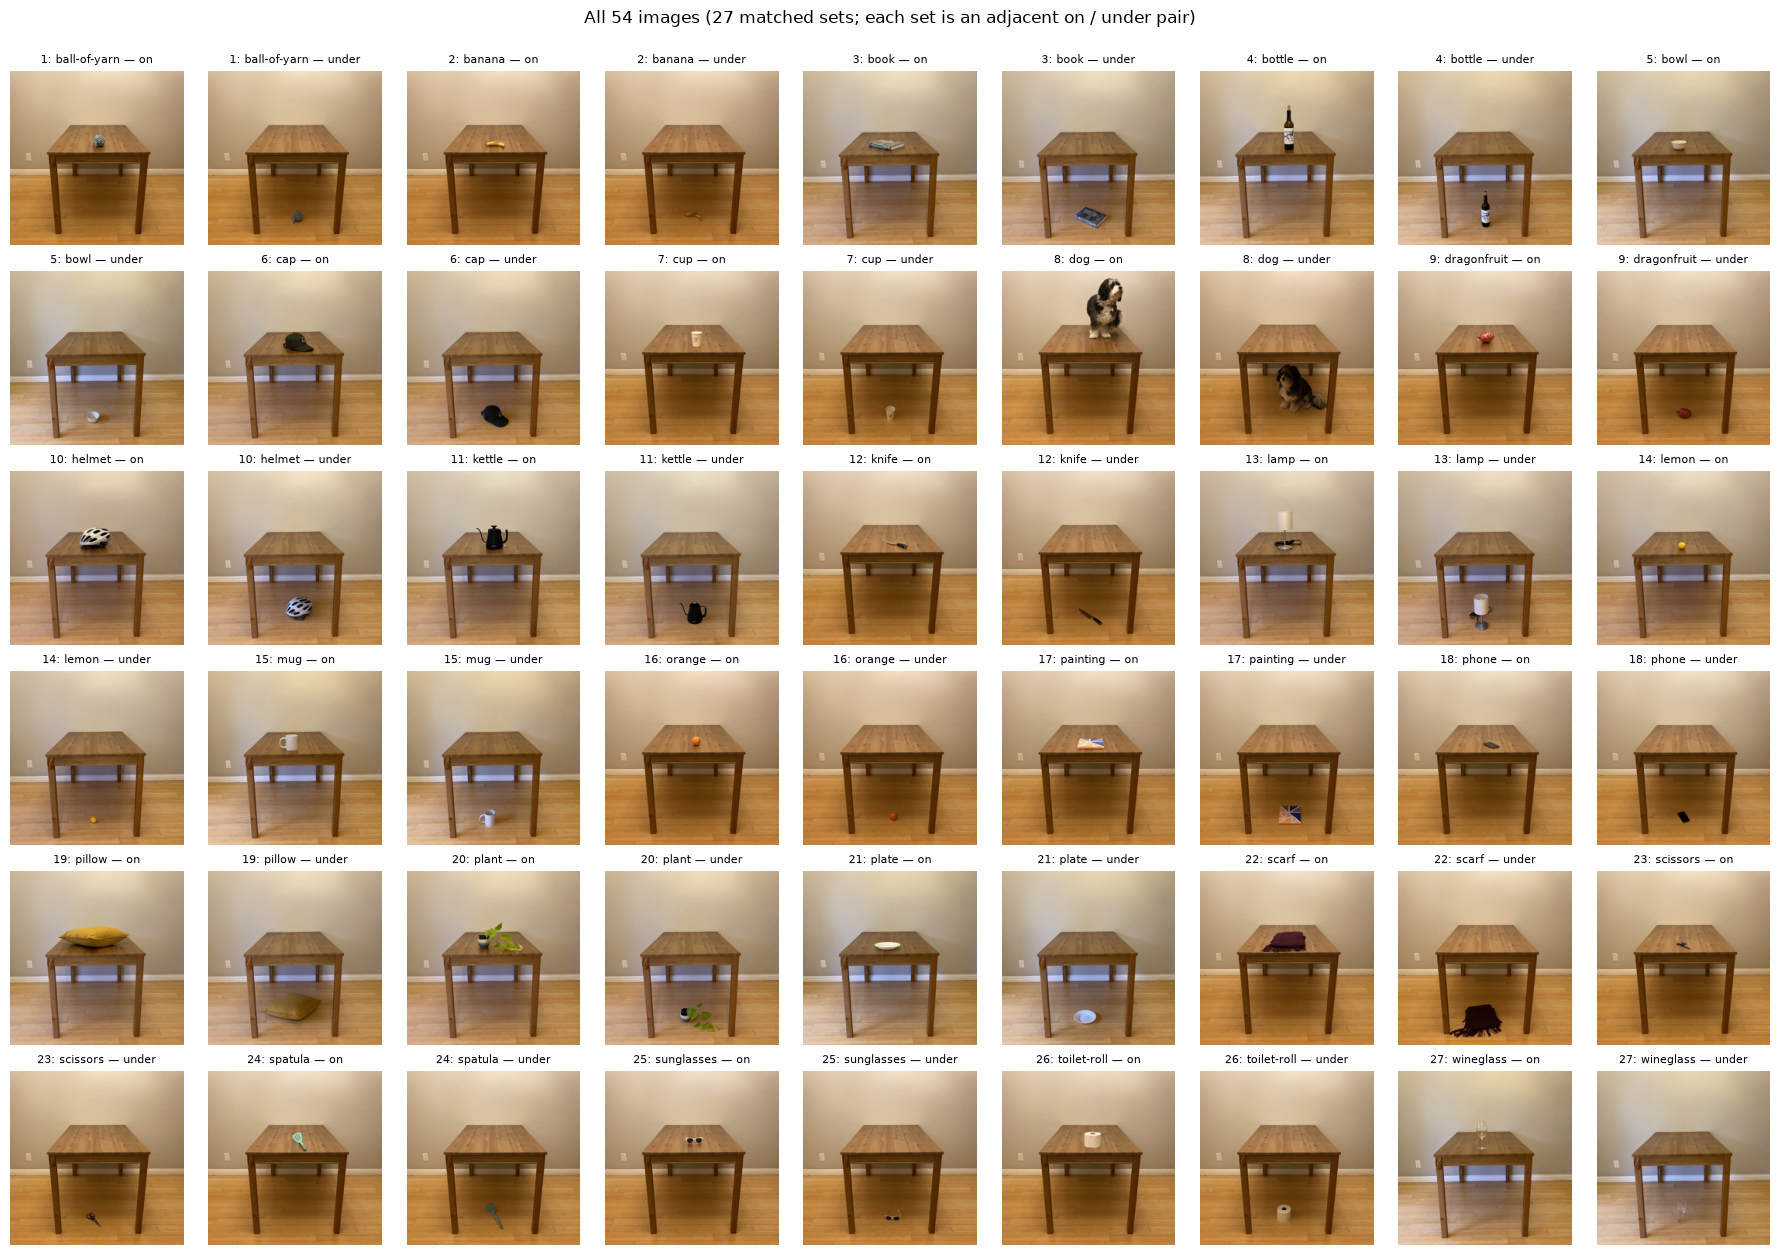

In [3]:
# Every image in the study, shown as the 224 x 224 centre crop that CLIP's preprocessing produces
fig, axes = plt.subplots(6, 9, figsize=(18, 12.5))
for k, row in pairs.iterrows():
    for j, rel in enumerate(("on", "under")):
        ax = axes.flat[2 * k + j]
        ax.imshow(ImageOps.fit(Image.open(ROOT / row[f"image_{rel}"]).convert("RGB"), (224, 224)))
        ax.set_title(f"{row.set_id}: {row.object} — {rel}", fontsize=8)
        ax.axis("off")
fig.suptitle(f"All {2 * N} images ({N} matched sets; each set is an adjacent on / under pair)", y=1.0)
plt.tight_layout()
plt.savefig(OUT / "task1_all_images.png", dpi=110, bbox_inches="tight")
plt.show()

### Things that could affect the results

The main ones are object height in the frame, background and shadow, small object size, and a likely preference for "on"; see the report for details.

## Encoders and similarity code

Same code as Part 2; decisions use cosine similarity directly, since the ×100 scale can't change a 2 × 2 comparison.

In [4]:
def l2_normalize(x, eps=1e-12):
    return x / x.norm(dim=-1, keepdim=True).clamp_min(eps)


def cosine_similarity_matrix(a, b):
    return l2_normalize(a) @ l2_normalize(b).T


@torch.no_grad()
def encode_images(files, batch_size=6):
    out = []
    for i in range(0, len(files), batch_size):
        images = [Image.open(ROOT / f).convert("RGB") for f in files[i:i + batch_size]]
        pixels = processor(images=images, return_tensors="pt")["pixel_values"].to(device)
        out.append(model.visual_projection(model.vision_model(pixel_values=pixels).pooler_output).cpu())
    return torch.cat(out)


@torch.no_grad()
def encode_texts(texts):
    tokens = processor(text=list(texts), padding=True, return_tensors="pt").to(device)
    pooled = model.text_model(input_ids=tokens["input_ids"], attention_mask=tokens["attention_mask"]).pooler_output
    return model.text_projection(pooled).cpu()


# order everywhere: [set1-on, set1-under, set2-on, set2-under, ...]
image_files = [f for _, r in pairs.iterrows() for f in (r.image_on, r.image_under)]
labels = [f"{r.object} / {rel}" for _, r in pairs.iterrows() for rel in ("on", "under")]

cache = OUT / "image_embeddings.npz"
if cache.exists() and list(np.load(cache, allow_pickle=False)["files"]) == image_files:
    image_emb = torch.from_numpy(np.load(cache, allow_pickle=False)["embeddings"])
    print("loaded cached image embeddings", tuple(image_emb.shape))
else:
    image_emb = encode_images(image_files)
    np.savez(cache, embeddings=image_emb.numpy(), files=np.array(image_files, dtype=str))
    print("computed and cached image embeddings", tuple(image_emb.shape))

computed and cached image embeddings (54, 512)


## Task 2 — Evaluate and visualize

### 2.1 The 2 × 2 similarity table for every set

Rows are the images (on, under), columns are the captions (on, under), and the correct matches are on the diagonal.

In [5]:
def evaluate(caption_on, caption_under, tag):
    """Score every comparison set with the given captions. Returns per-set results and the (N, 2, 2) similarities."""
    texts = [t for a, b in zip(caption_on, caption_under) for t in (a, b)]
    text_emb = encode_texts(texts)
    full = cosine_similarity_matrix(image_emb, text_emb).numpy()   # (2N, 2N)
    S = np.stack([full[2 * k:2 * k + 2, 2 * k:2 * k + 2] for k in range(N)])
    res = pd.DataFrame({
        "set_id": pairs.set_id, "object": pairs.object,
        "sim_imgOn_txtOn": S[:, 0, 0], "sim_imgOn_txtUnder": S[:, 0, 1],
        "sim_imgUnder_txtOn": S[:, 1, 0], "sim_imgUnder_txtUnder": S[:, 1, 1],
    })
    res["on_image_correct"] = S[:, 0, 0] > S[:, 0, 1]
    res["under_image_correct"] = S[:, 1, 1] > S[:, 1, 0]
    res["both_images_correct"] = res.on_image_correct & res.under_image_correct
    res["on_text_correct"] = S[:, 0, 0] > S[:, 1, 0]       # description-to-image
    res["under_text_correct"] = S[:, 1, 1] > S[:, 0, 1]
    res["margin_on_image"] = S[:, 0, 0] - S[:, 0, 1]       # correct minus wrong description
    res["margin_under_image"] = S[:, 1, 1] - S[:, 1, 0]
    res.round(5).to_csv(OUT / f"{tag}_per_set_results.csv", index=False)
    np.save(OUT / f"{tag}_similarity_2x2.npy", S)
    return res, S, text_emb, texts


def binom_two_sided_p(k, n, p=0.5):
    """Exact two-sided binomial test against chance."""
    pmf = [comb(n, i) * p ** i * (1 - p) ** (n - i) for i in range(n + 1)]
    return min(1.0, sum(x for x in pmf if x <= pmf[k] + 1e-12))


def summarize(res, name):
    n_img = 2 * len(res)
    correct = int(res.on_image_correct.sum() + res.under_image_correct.sum())
    t_correct = int(res.on_text_correct.sum() + res.under_text_correct.sum())
    return {
        "condition": name,
        "image-to-description correct": f"{correct}/{n_img}",
        "image-to-description accuracy": correct / n_img,
        "'on' images correct": f"{int(res.on_image_correct.sum())}/{len(res)}",
        "'under' images correct": f"{int(res.under_image_correct.sum())}/{len(res)}",
        "sets with both images correct": f"{int(res.both_images_correct.sum())}/{len(res)}",
        "images assigned the 'on' description": f"{int(res.on_image_correct.sum() + (~res.under_image_correct).sum())}/{n_img}",
        "description-to-image accuracy": t_correct / n_img,
        "p-value vs 50% (exact binomial)": binom_two_sided_p(correct, n_img),
        "mean margin": float(np.r_[res.margin_on_image, res.margin_under_image].mean()),
    }


base, S_base, text_emb_base, texts_base = evaluate(pairs.caption_on, pairs.caption_under, "task2_baseline")
base_summary = summarize(base, "baseline captions: 'on' / 'under'")
pd.Series(base_summary).to_frame("value")

,value
condition,baseline captions: 'on' / 'under'
image-to-description correct,35/54
image-to-description accuracy,0.648148
'on' images correct,20/27
'under' images correct,15/27
sets with both images correct,8/27
images assigned the 'on' description,32/54
description-to-image accuracy,0.62963
p-value vs 50% (exact binomial),0.040224
mean margin,0.004545


Chance is 50% per image and 25% for getting both images in a set right.

In [6]:
with pd.option_context("display.max_rows", 100, "display.width", 250):
    display(base[["set_id", "object", "sim_imgOn_txtOn", "sim_imgOn_txtUnder", "sim_imgUnder_txtOn",
                  "sim_imgUnder_txtUnder", "on_image_correct", "under_image_correct", "both_images_correct"]].round(4))

,set_id,object,sim_imgOn_txtOn,sim_imgOn_txtUnder,sim_imgUnder_txtOn,sim_imgUnder_txtUnder,on_image_correct,under_image_correct,both_images_correct
0,1,ball-of-yarn,0.2574,0.2589,0.2559,0.2625,False,True,False
1,2,banana,0.2902,0.2812,0.2671,0.2667,True,False,False
2,3,book,0.2931,0.2822,0.3137,0.3036,True,False,False
3,4,bottle,0.3033,0.3018,0.3009,0.3058,True,True,True
4,5,bowl,0.2775,0.2872,0.2733,0.2905,False,True,False
5,6,cap,0.3128,0.3019,0.2832,0.2900,True,True,True
6,7,cup,0.2927,0.3011,0.2982,0.3074,False,True,False
7,8,dog,0.3259,0.2862,0.3143,0.3024,True,False,False
8,9,dragonfruit,0.2801,0.2699,0.2718,0.2652,True,False,False
9,10,helmet,0.3303,0.3052,0.2865,0.2880,True,True,True


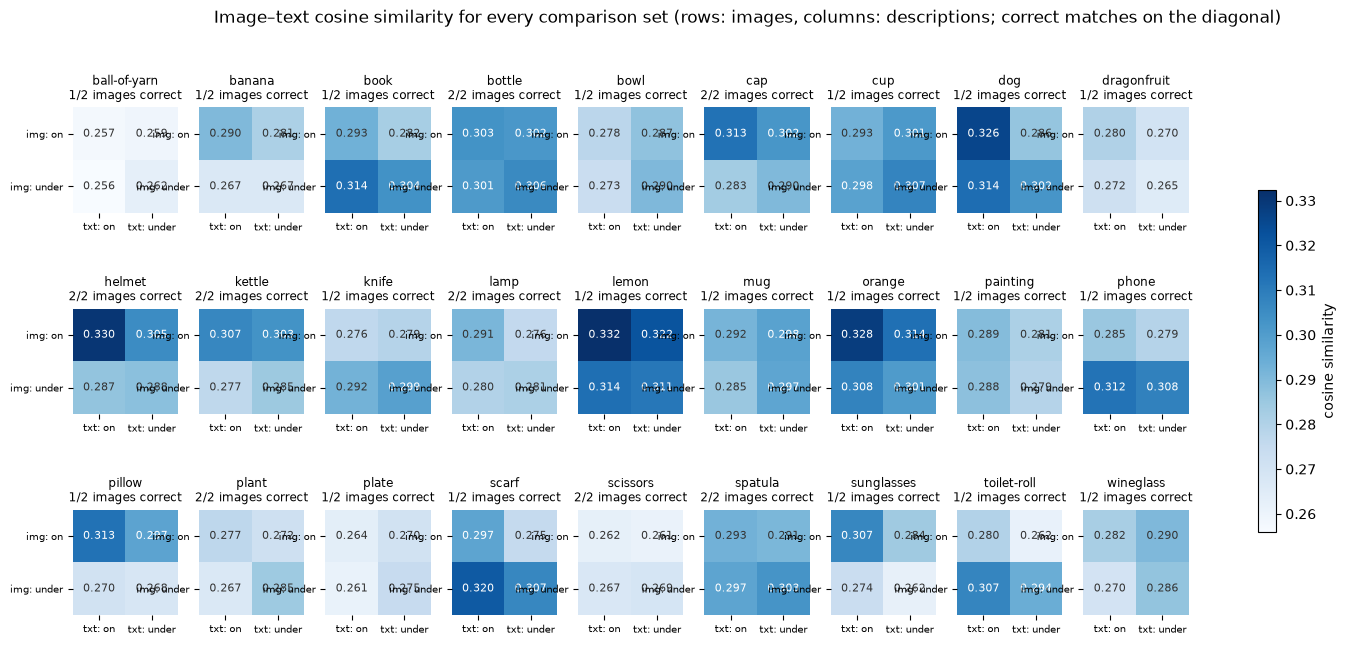

In [7]:
def plot_all_2x2(S, res, title, path):
    """Small multiples: one 2 x 2 similarity matrix per comparison set, on a shared colour scale."""
    fig, axes = plt.subplots(3, 9, figsize=(18, 7.4))
    vmin, vmax = S.min(), S.max()
    for k, ax in enumerate(axes.flat):
        im = ax.imshow(S[k], cmap="Blues", vmin=vmin, vmax=vmax)
        for (r, c), v in np.ndenumerate(S[k]):
            ax.text(c, r, f"{v:.3f}", ha="center", va="center", fontsize=8,
                    color="white" if v > (vmin + vmax) / 2 else "#333333")
        n_ok = int(res.on_image_correct[k]) + int(res.under_image_correct[k])
        ax.set_title(f"{res.object[k]}\n{n_ok}/2 images correct", fontsize=8.5)
        ax.set_xticks([0, 1], ["txt: on", "txt: under"], fontsize=7)
        ax.set_yticks([0, 1], ["img: on", "img: under"], fontsize=7)
        for s in ax.spines.values():
            s.set_visible(False)
    fig.colorbar(im, ax=axes, shrink=0.6, label="cosine similarity")
    fig.suptitle(title, y=0.97)
    plt.savefig(path, dpi=130, bbox_inches="tight")
    plt.show()


plot_all_2x2(S_base, base, "Image–text cosine similarity for every comparison set (rows: images, columns: descriptions; correct matches on the diagonal)",
             OUT / "task2_all_2x2_matrices.png")

### 2.2 Margins for every image

Margin = similarity to the correct caption minus similarity to the wrong one (positive means correct).

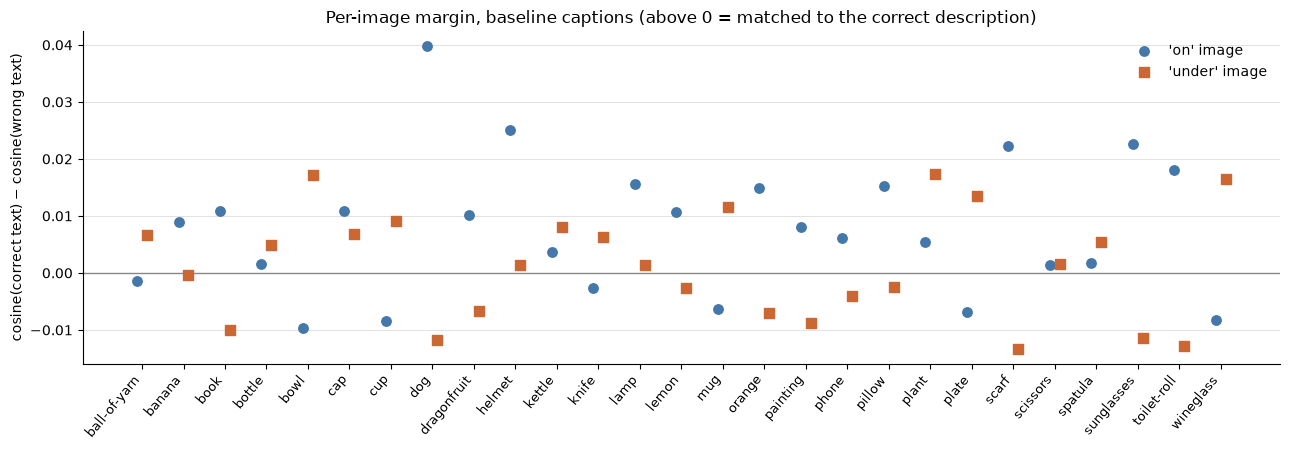

margin over all 54 images: mean +0.0045, min -0.0133, max +0.0397, mean |margin| 0.0096
mean margin, 'on' images: +0.0078 | 'under' images: +0.0013
mean cosine of an image to its correct description: 0.2913


In [8]:
def plot_margins(res, title, path):
    fig, ax = plt.subplots(figsize=(13, 4.6))
    x = np.arange(len(res))
    ax.axhline(0, color="#888888", lw=1)
    ax.scatter(x - 0.12, res.margin_on_image, s=46, marker="o", color="#4477aa", label="'on' image", zorder=3)
    ax.scatter(x + 0.12, res.margin_under_image, s=46, marker="s", color="#cc6633", label="'under' image", zorder=3)
    ax.set_xticks(x, res.object, rotation=50, ha="right", fontsize=9)
    ax.set_ylabel("cosine(correct text) − cosine(wrong text)")
    ax.set_title(title)
    ax.legend(frameon=False, loc="upper right")
    ax.grid(axis="y", color="#dddddd", lw=0.6)
    ax.set_axisbelow(True)
    for s in ("top", "right"):
        ax.spines[s].set_visible(False)
    plt.tight_layout()
    plt.savefig(path, dpi=140, bbox_inches="tight")
    plt.show()


plot_margins(base, "Per-image margin, baseline captions (above 0 = matched to the correct description)", OUT / "task2_margins.png")
m = np.r_[base.margin_on_image, base.margin_under_image]
print(f"margin over all {m.size} images: mean {m.mean():+.4f}, min {m.min():+.4f}, max {m.max():+.4f}, mean |margin| {np.abs(m).mean():.4f}")
print(f"mean margin, 'on' images: {base.margin_on_image.mean():+.4f} | 'under' images: {base.margin_under_image.mean():+.4f}")
print(f"mean cosine of an image to its correct description: {np.r_[S_base[:, 0, 0], S_base[:, 1, 1]].mean():.4f}")

### 2.3 Similarity among the text descriptions

In [9]:
text_sim = cosine_similarity_matrix(text_emb_base, text_emb_base).numpy()
np.save(OUT / "task2_text_text_similarity.npy", text_sim)

obj_id = np.repeat(np.arange(N), 2)
rel_id = np.tile([0, 1], N)
upper = np.triu(np.ones_like(text_sim, dtype=bool), k=1)
same_obj = obj_id[:, None] == obj_id[None, :]
same_rel = rel_id[:, None] == rel_id[None, :]
groups = {
    "same object, different relation (the two captions of a set)": text_sim[upper & same_obj],
    "different object, same relation": text_sim[upper & ~same_obj & same_rel],
    "different object, different relation": text_sim[upper & ~same_obj & ~same_rel],
}
text_stats = pd.DataFrame([{"caption pairs": k, "n": v.size, "mean cosine": v.mean(), "min": v.min(), "max": v.max()}
                           for k, v in groups.items()]).round(4)
text_stats.to_csv(OUT / "task2_text_similarity_summary.csv", index=False)
text_stats

,caption pairs,n,mean cosine,min,max
0,"same object, different relation (the two capti...",27,0.9256,0.8471,0.9507
1,"different object, same relation",702,0.8036,0.6114,0.9511
2,"different object, different relation",702,0.7396,0.5610,0.8964


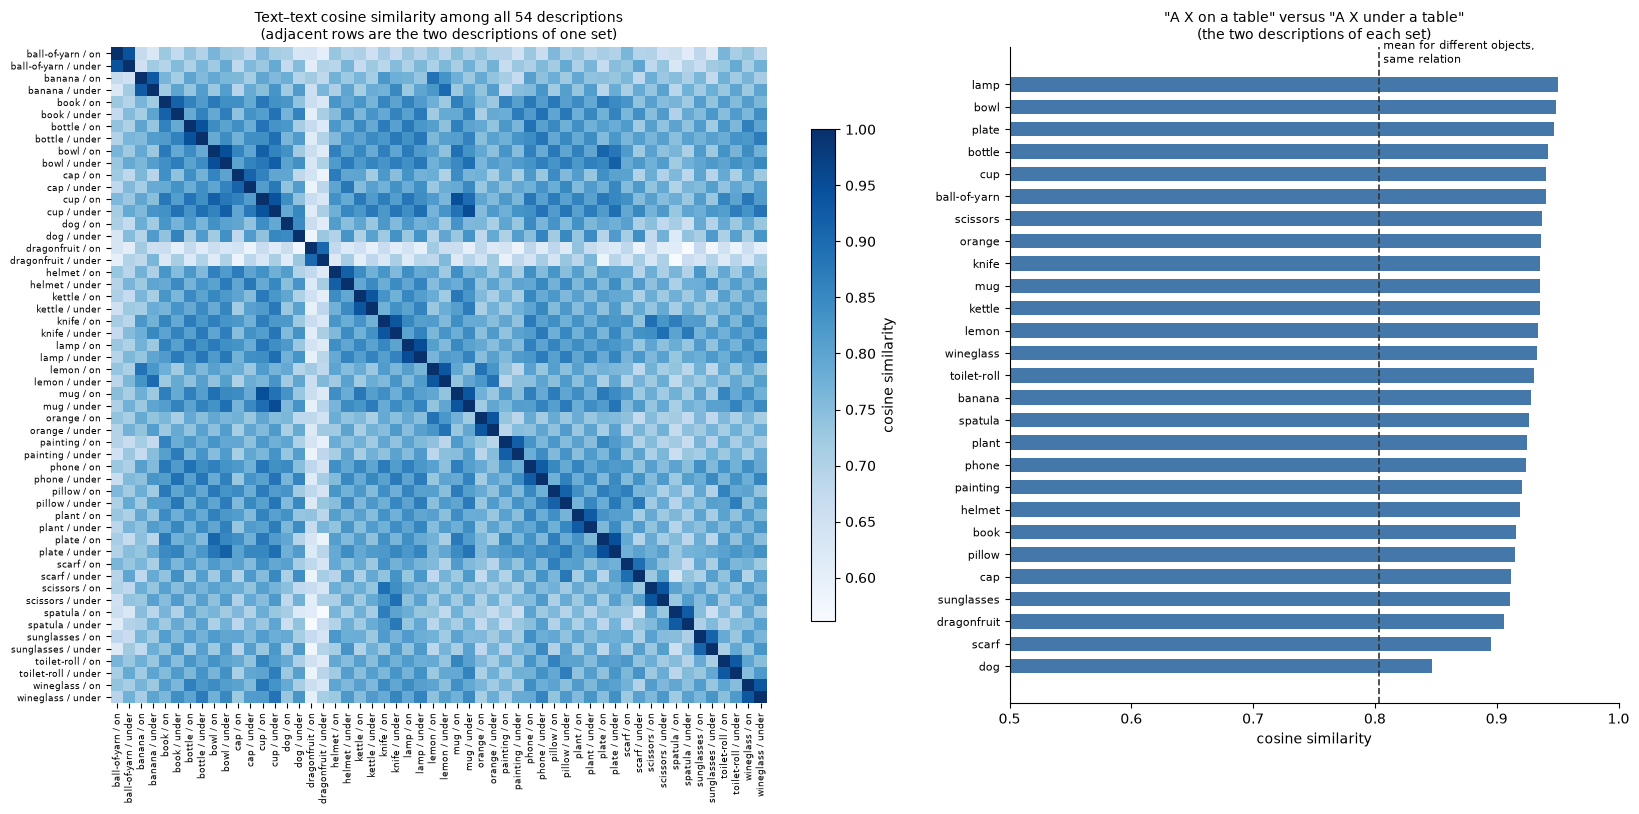

text:  two descriptions of a set  mean cosine 0.9256 (min 0.8471, max 0.9507)
image: two images of a set        mean cosine 0.9672 (min 0.9264, max 0.9898)
image: images of different objects mean cosine 0.9298


In [10]:
fig, axes = plt.subplots(1, 2, figsize=(17, 8), gridspec_kw={"width_ratios": [1.45, 1]})
im = axes[0].imshow(text_sim, cmap="Blues", vmin=text_sim.min(), vmax=1.0)
axes[0].set_xticks(range(2 * N), labels, rotation=90, fontsize=6.5)
axes[0].set_yticks(range(2 * N), labels, fontsize=6.5)
axes[0].set_title(f"Text–text cosine similarity among all {2 * N} descriptions\n(adjacent rows are the two descriptions of one set)", fontsize=10)
fig.colorbar(im, ax=axes[0], shrink=0.75, label="cosine similarity")
for s in axes[0].spines.values():
    s.set_visible(False)

within_set = text_sim[np.arange(0, 2 * N, 2), np.arange(1, 2 * N, 2)]
order = np.argsort(within_set)
axes[1].barh(np.arange(N), within_set[order], color="#4477aa", height=0.65)
axes[1].axvline(groups["different object, same relation"].mean(), color="#333333", lw=1.2, ls="--")
axes[1].text(groups["different object, same relation"].mean(), N - 0.2, " mean for different objects,\n same relation", fontsize=8, va="bottom")
axes[1].set_yticks(np.arange(N), pairs.object[order], fontsize=8)
axes[1].set_xlim(min(0.5, text_sim.min()), 1.0)
axes[1].set_xlabel("cosine similarity")
axes[1].set_title('"A X on a table" versus "A X under a table"\n(the two descriptions of each set)', fontsize=10)
for s in ("top", "right"):
    axes[1].spines[s].set_visible(False)
plt.tight_layout()
plt.savefig(OUT / "task2_text_similarity.png", dpi=130, bbox_inches="tight")
plt.show()

# For comparison: how similar are the two IMAGES of a set?
img_sim = cosine_similarity_matrix(image_emb, image_emb).numpy()
img_within = img_sim[np.arange(0, 2 * N, 2), np.arange(1, 2 * N, 2)]
img_cross = img_sim[upper & ~same_obj]
print(f"text:  two descriptions of a set  mean cosine {within_set.mean():.4f} (min {within_set.min():.4f}, max {within_set.max():.4f})")
print(f"image: two images of a set        mean cosine {img_within.mean():.4f} (min {img_within.min():.4f}, max {img_within.max():.4f})")
print(f"image: images of different objects mean cosine {img_cross.mean():.4f}")

### 2.4 Successful and unsuccessful comparisons

sets with both images correct (8): ['bottle', 'cap', 'helmet', 'kettle', 'lamp', 'plant', 'scissors', 'spatula']
sets with at least one image wrong (19): ['ball-of-yarn', 'banana', 'book', 'bowl', 'cup', 'dog', 'dragonfruit', 'knife', 'lemon', 'mug', 'orange', 'painting', 'phone', 'pillow', 'plate', 'scarf', 'sunglasses', 'toilet-roll', 'wineglass']
sets with both images wrong: []


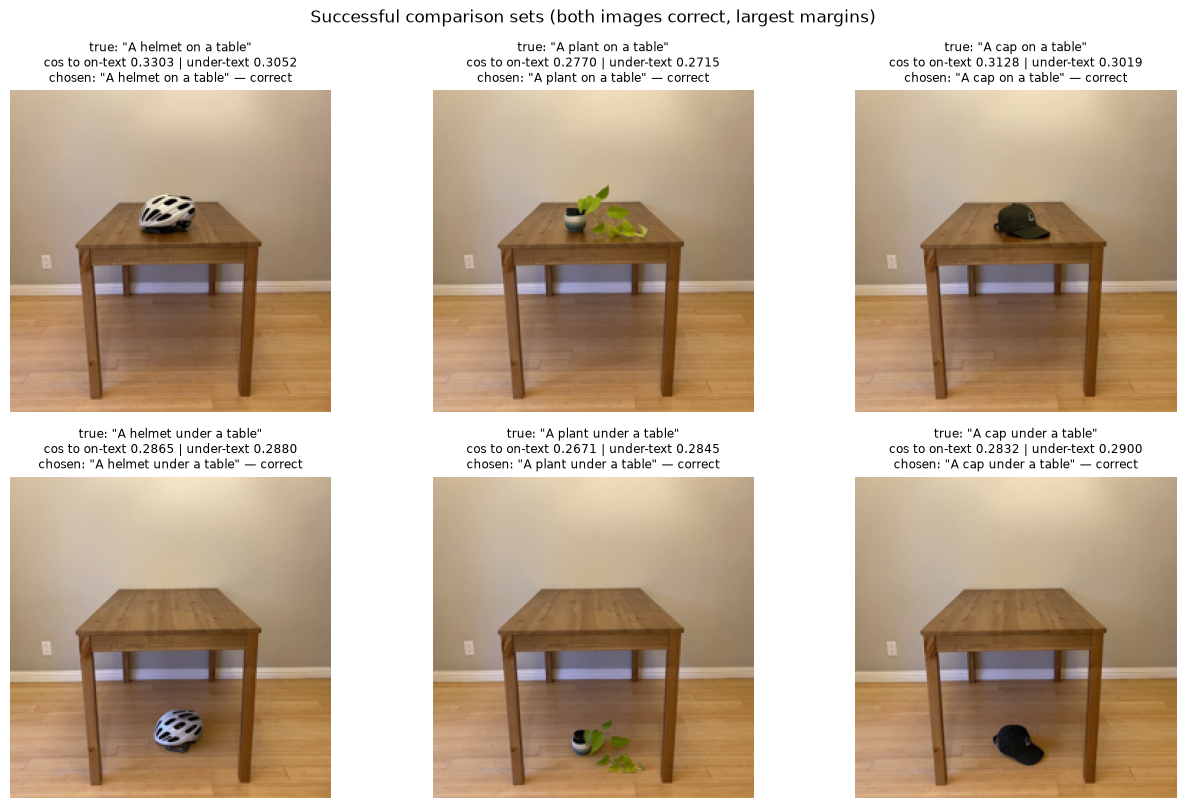

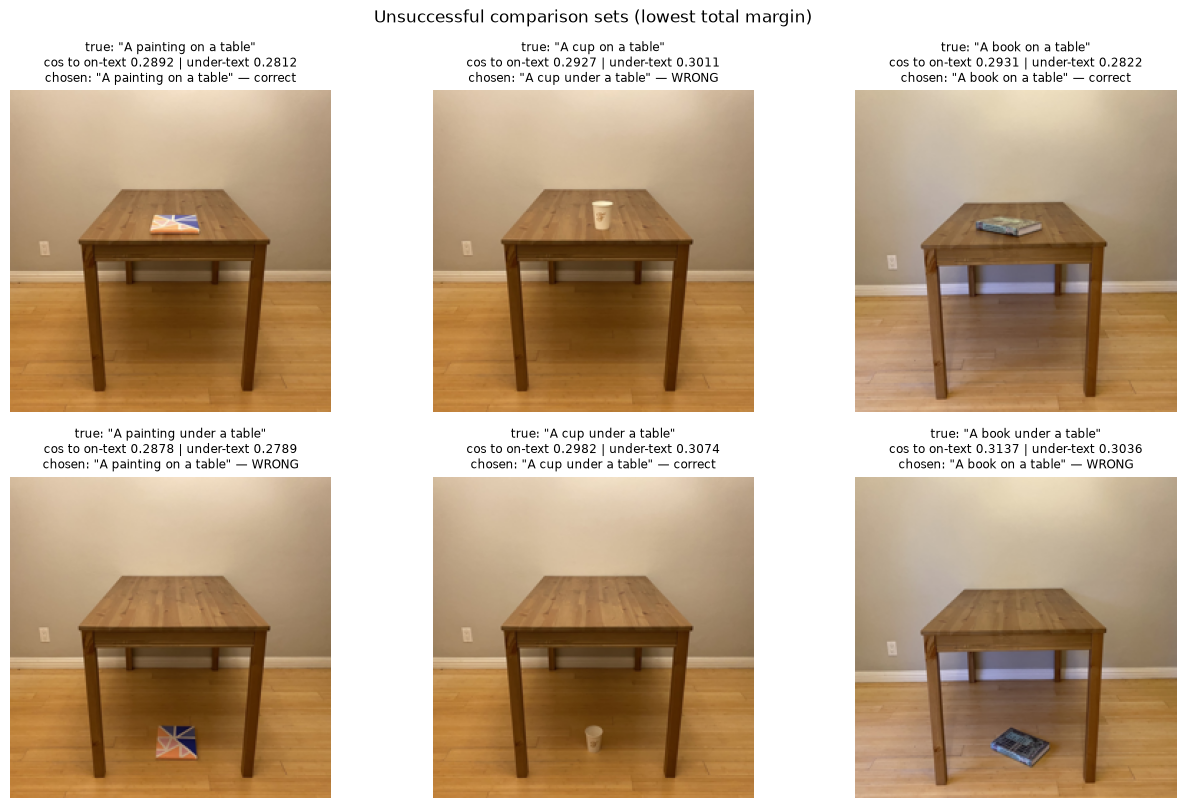

In [11]:
def show_sets(res, S, set_indices, title, path, captions=None):
    captions = captions if captions is not None else (pairs.caption_on, pairs.caption_under)
    fig, axes = plt.subplots(2, len(set_indices), figsize=(4.3 * len(set_indices), 8.2), squeeze=False)
    for col, k in enumerate(set_indices):
        for row, rel in enumerate(("on", "under")):
            ax = axes[row, col]
            ax.imshow(ImageOps.fit(Image.open(ROOT / pairs[f"image_{rel}"][k]).convert("RGB"), (224, 224)))
            ok = res[f"{rel}_image_correct"][k]
            chosen = captions[int(np.argmax(S[k, row]))][k]
            ax.set_title(f'true: "{captions[row][k]}"\ncos to on-text {S[k, row, 0]:.4f} | under-text {S[k, row, 1]:.4f}\n'
                         f'chosen: "{chosen}" — {"correct" if ok else "WRONG"}', fontsize=8.5)
            ax.axis("off")
    fig.suptitle(title)
    plt.tight_layout()
    plt.savefig(path, dpi=120, bbox_inches="tight")
    plt.show()


set_margin = base.margin_on_image + base.margin_under_image
both_ok = base.index[base.both_images_correct].tolist()
not_ok = base.index[~base.both_images_correct].tolist()
print(f"sets with both images correct ({len(both_ok)}):", base.object[both_ok].tolist())
print(f"sets with at least one image wrong ({len(not_ok)}):", base.object[not_ok].tolist())
print(f"sets with both images wrong: {base.object[~base.on_image_correct & ~base.under_image_correct].tolist()}")

if both_ok:
    best = sorted(both_ok, key=lambda k: -set_margin[k])[:3]
    show_sets(base, S_base, best, "Successful comparison sets (both images correct, largest margins)", OUT / "task2_examples_success.png")
if not_ok:
    worst = sorted(not_ok, key=lambda k: set_margin[k])[:3]
    show_sets(base, S_base, worst, "Unsuccessful comparison sets (lowest total margin)", OUT / "task2_examples_failure.png")

### 2.5 Task 2 discussion

35 of 54 images (64.8%) and 8 of 27 sets are fully correct, with tiny margins, so H1 is partly supported. See the report for the full discussion.

## Task 3 — Test one explanation

Replace "on" with "on top of" and "under" with "underneath" in every caption, keeping everything else the same, to test whether clearer wording helps.

In [12]:
cap_on_new = pairs.caption_on.str.replace(" on a table", " on top of a table", regex=False)
cap_under_new = pairs.caption_under.str.replace(" under a table", " underneath a table", regex=False)
assert cap_on_new.str.contains("on top of").all() and cap_under_new.str.contains("underneath").all()
print("example:", repr(cap_on_new[14]), "|", repr(cap_under_new[14]))

new, S_new, text_emb_new, texts_new = evaluate(cap_on_new, cap_under_new, "task3_changed")
new_summary = summarize(new, "changed captions: 'on top of' / 'underneath'")
comparison = pd.DataFrame([base_summary, new_summary]).set_index("condition").T
comparison.to_csv(OUT / "task3_comparison.csv")
comparison

example: 'A mug on top of a table' | 'A mug underneath a table'


condition,baseline captions: 'on' / 'under',changed captions: 'on top of' / 'underneath'
image-to-description correct,35/54,34/54
image-to-description accuracy,0.648148,0.62963
'on' images correct,20/27,14/27
'under' images correct,15/27,20/27
sets with both images correct,8/27,8/27
images assigned the 'on' description,32/54,21/54
description-to-image accuracy,0.62963,0.611111
p-value vs 50% (exact binomial),0.040224,0.075905
mean margin,0.004545,0.002783


In [13]:
# Paired view: what happened to each of the 54 image decisions?
b = np.r_[base.on_image_correct, base.under_image_correct]
n = np.r_[new.on_image_correct, new.under_image_correct]
flips = pd.DataFrame({"count": {
    "correct in both conditions": int((b & n).sum()),
    "wrong in both conditions": int((~b & ~n).sum()),
    "fixed by the change (wrong -> correct)": int((~b & n).sum()),
    "broken by the change (correct -> wrong)": int((b & ~n).sum()),
}})
flips.to_csv(OUT / "task3_paired_flips.csv")
display(flips)

n_fix, n_break = int((~b & n).sum()), int((b & ~n).sum())
if n_fix + n_break:
    print(f"exact sign test on the {n_fix + n_break} decisions that changed: p = {binom_two_sided_p(n_fix, n_fix + n_break):.3f}")

text_sim_new = cosine_similarity_matrix(text_emb_new, text_emb_new).numpy()
within_new = text_sim_new[np.arange(0, 2 * N, 2), np.arange(1, 2 * N, 2)]
print(f"\nmean cosine between the two descriptions of a set: baseline {within_set.mean():.4f} -> changed {within_new.mean():.4f}")
m_new = np.r_[new.margin_on_image, new.margin_under_image]
print(f"mean margin: baseline {m.mean():+.4f} -> changed {m_new.mean():+.4f}")
print(f"mean margin, 'on' images:    baseline {base.margin_on_image.mean():+.4f} -> changed {new.margin_on_image.mean():+.4f}")
print(f"mean margin, 'under' images: baseline {base.margin_under_image.mean():+.4f} -> changed {new.margin_under_image.mean():+.4f}")

per_set = pd.DataFrame({
    "object": pairs.object,
    "baseline on-img": base.on_image_correct, "baseline under-img": base.under_image_correct,
    "changed on-img": new.on_image_correct, "changed under-img": new.under_image_correct,
    "baseline margin (on img)": base.margin_on_image.round(4), "changed margin (on img)": new.margin_on_image.round(4),
    "baseline margin (under img)": base.margin_under_image.round(4), "changed margin (under img)": new.margin_under_image.round(4),
})
per_set.to_csv(OUT / "task3_per_set_comparison.csv", index=False)
with pd.option_context("display.max_rows", 100, "display.width", 250):
    display(per_set)

,count
correct in both conditions,22
wrong in both conditions,7
fixed by the change (wrong -> correct),12
broken by the change (correct -> wrong),13


exact sign test on the 25 decisions that changed: p = 1.000

mean cosine between the two descriptions of a set: baseline 0.9256 -> changed 0.9154
mean margin: baseline +0.0045 -> changed +0.0028
mean margin, 'on' images:    baseline +0.0078 -> changed +0.0009
mean margin, 'under' images: baseline +0.0013 -> changed +0.0047


,object,baseline on-img,baseline under-img,changed on-img,changed under-img,baseline margin (on img),changed margin (on img),baseline margin (under img),changed margin (under img)
0,ball-of-yarn,False,True,False,True,-0.0015,-0.0103,0.0066,0.0151
1,banana,True,False,False,True,0.0090,-0.0091,-0.0004,0.0127
2,book,True,False,False,False,0.0109,-0.0024,-0.0101,-0.0020
3,bottle,True,True,False,True,0.0015,-0.0001,0.0049,0.0021
4,bowl,False,True,False,True,-0.0096,-0.0058,0.0171,0.0054
5,cap,True,True,True,True,0.0109,0.0084,0.0068,0.0004
6,cup,False,True,False,True,-0.0084,-0.0070,0.0092,0.0045
7,dog,True,False,True,True,0.0397,0.0147,-0.0118,0.0144
8,dragonfruit,True,False,False,True,0.0102,-0.0114,-0.0066,0.0147
9,helmet,True,True,True,False,0.0251,0.0161,0.0014,-0.0020


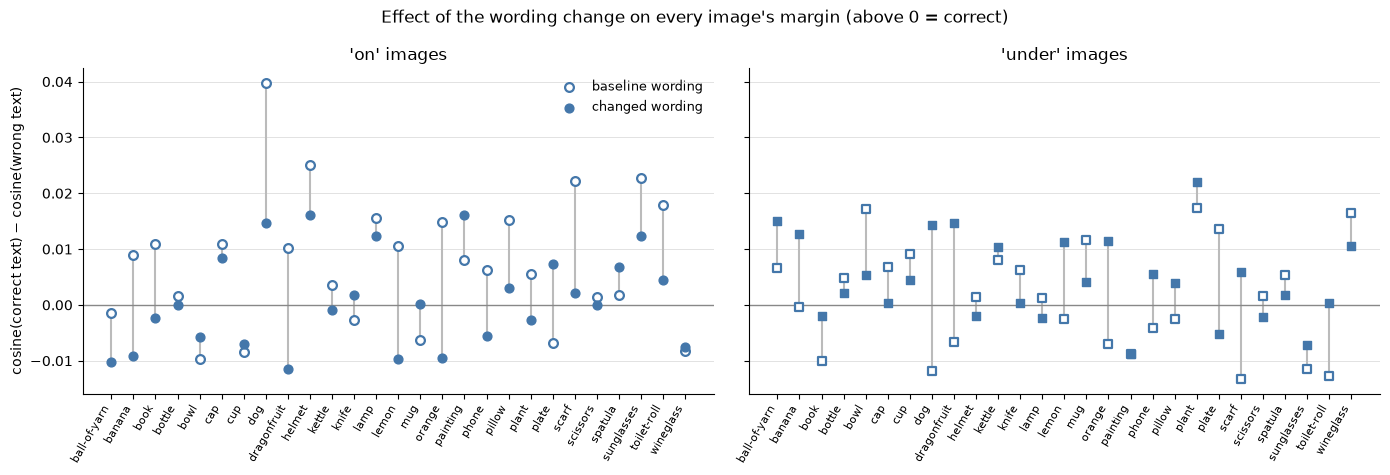

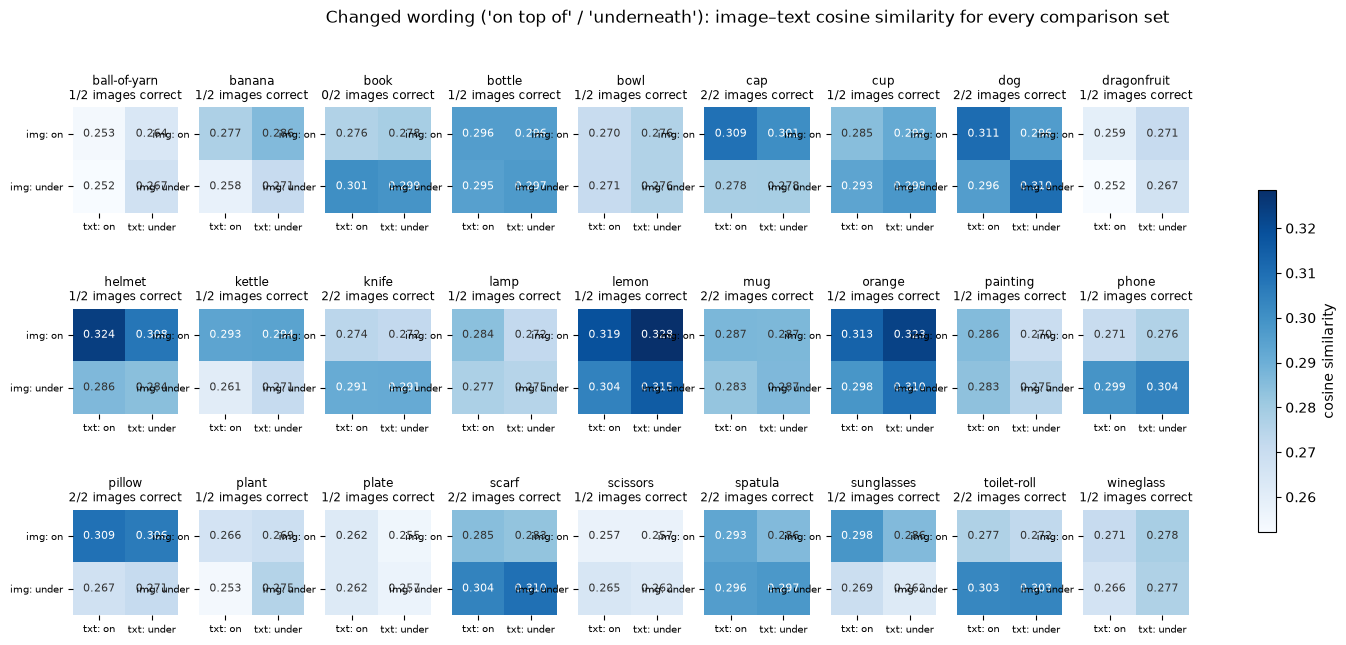

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8), sharey=True)
x = np.arange(N)
for ax, rel, marker in zip(axes, ("on", "under"), ("o", "s")):
    mb, mn = base[f"margin_{rel}_image"], new[f"margin_{rel}_image"]
    ax.axhline(0, color="#888888", lw=1)
    ax.vlines(x, mb, mn, color="#bbbbbb", lw=1.5, zorder=1)
    ax.scatter(x, mb, s=40, marker=marker, facecolor="white", edgecolor="#4477aa", linewidth=1.6, label="baseline wording", zorder=3)
    ax.scatter(x, mn, s=40, marker=marker, color="#4477aa", label="changed wording", zorder=3)
    ax.set_xticks(x, pairs.object, rotation=60, ha="right", fontsize=8)
    ax.set_title(f"'{rel}' images")
    ax.grid(axis="y", color="#dddddd", lw=0.6)
    ax.set_axisbelow(True)
    for s in ("top", "right"):
        ax.spines[s].set_visible(False)
axes[0].set_ylabel("cosine(correct text) − cosine(wrong text)")
axes[0].legend(frameon=False, fontsize=9)
fig.suptitle("Effect of the wording change on every image's margin (above 0 = correct)")
plt.tight_layout()
plt.savefig(OUT / "task3_margin_change.png", dpi=140, bbox_inches="tight")
plt.show()

plot_all_2x2(S_new, new, "Changed wording ('on top of' / 'underneath'): image–text cosine similarity for every comparison set",
             OUT / "task3_all_2x2_matrices.png")

### Extra check: is "on" vs. "under" in the image vectors at all?

Using only image embeddings, an "on minus under" direction from the other 26 sets is used to order each left-out set.

In [15]:
I = l2_normalize(image_emb).numpy()
diff = I[0::2] - I[1::2]                       # (N, 512): on-image minus under-image, per set

loo_correct, loo_gap = [], []
for k in range(N):
    direction = np.delete(diff, k, axis=0).mean(0)
    gap = float(I[2 * k] @ direction - I[2 * k + 1] @ direction)
    loo_gap.append(gap)
    loo_correct.append(gap > 0)
print(f"leave-one-set-out, image embeddings only: {sum(loo_correct)}/{N} sets ordered correctly"
      f" (p = {binom_two_sided_p(sum(loo_correct), N):.2g} vs 50%)")
print("sets ordered incorrectly:", pairs.object[~np.array(loo_correct)].tolist())

# How consistent is the image difference direction across sets, and does the text difference point the same way?
unit = lambda v: v / np.linalg.norm(v, axis=-1, keepdims=True)
d_img = unit(diff)
pairwise = (d_img @ d_img.T)[np.triu(np.ones((N, N), dtype=bool), k=1)]
T = l2_normalize(text_emb_base).numpy()
t_diff = T[0::2] - T[1::2]                     # on-text minus under-text, per set
d_txt = unit(t_diff)
pairwise_t = (d_txt @ d_txt.T)[np.triu(np.ones((N, N), dtype=bool), k=1)]
align = (d_img * d_txt).sum(1)                 # per set: cosine between image difference and text difference
print(f"\nmean pairwise cosine between sets' image difference vectors: {pairwise.mean():.3f}")
print(f"mean pairwise cosine between sets' text difference vectors:  {pairwise_t.mean():.3f}")
print(f"cosine between a set's image difference and its text difference: mean {align.mean():+.3f}, range {align.min():+.3f} to {align.max():+.3f}")
print(f"norm of the image difference (unit embeddings): mean {np.linalg.norm(diff, axis=1).mean():.3f}"
      f" | norm of the text difference: mean {np.linalg.norm(t_diff, axis=1).mean():.3f}")
pd.DataFrame({"object": pairs.object, "loo_projection_gap": np.round(loo_gap, 4), "loo_correct": loo_correct,
              "image_text_difference_cosine": align.round(4)}).to_csv(OUT / "task3_supplementary_image_direction.csv", index=False)

leave-one-set-out, image embeddings only: 27/27 sets ordered correctly (p = 1.5e-08 vs 50%)
sets ordered incorrectly: []

mean pairwise cosine between sets' image difference vectors: 0.202
mean pairwise cosine between sets' text difference vectors:  0.875
cosine between a set's image difference and its text difference: mean +0.091, range -0.006 to +0.218
norm of the image difference (unit embeddings): mean 0.247 | norm of the text difference: mean 0.383


### Task 3 discussion

Clearer wording didn't help (34/54 images, 8/27 sets); it only flipped which caption CLIP prefers. See the report for the full discussion.